# Are customers getting the full recovery — without a longer wait?
## A weekly check-in for Care leaders
**A manually refreshed monitoring feed.** This notebook updates when you supply new exports and run it; it does not refresh continuously. The saved example still uses operating records through September 30, 2026.

Use this notebook to answer three questions:
1. **Is the queue getting harder to manage?** Check call volume, time handling calls, and callers leaving before help.
2. **Are eligible customers receiving both parts of recovery?** Check replacement **and** Plus together.
3. **What needs attention?** Review warnings, then ask Quality or Workforce Management to investigate.

The results are already displayed. You do not need to edit code to read them. A colleague refreshing the report can change the queue, dates, and review settings in the next cell, then Run All. The default compares the latest seven available days with August. Thresholds are proposed discussion points, not agreed service targets.

**Quick glossary:** “eligible” means the serial result qualifies the hub for the approved offer; “complete recovery” means replacement and Plus are both recorded complete; “sample” means only some calls were examined. A warning means investigate, not that a particular Guide is at fault.

## Before you refresh: update the files, change the settings, then Run All
You can use this notebook for ongoing progress reviews. No connection to Orbit or another live system has been configured. Each run takes a fresh look at the Excel files you provide.

### Step 1 — Get a complete, consistent set of exports
Save the previous exports outside the active input folder so you can recover them. Put the new files in **`northstar_analysis/data/raw/`**, or use a separate folder and enter its path in **EDIT HERE — refresh settings** below.

| File to supply | Sheets that must remain available | What it updates |
|---|---|---|
| `Orbit_operations.xlsx` | `Daily operations`, `Call sample`, `Staffing`, `Product catalog` | Call volume, handling time, waiting, staffing, and sampled recovery actions |
| `Quality_and_feedback.xlsx` | `QA reviews`, `Customer feedback` | Selected quality checks and voluntary customer ratings |

**Replace each workbook with a full updated export, not just the newest rows.** Keep enough history for your baseline and weekly charts. The notebook does not append files or remember previous imports. Preserve sheet names, column names, identifiers, and Yes/No values. It finds the header row automatically. Both sources should come from a coordinated extract; newer QA or feedback IDs must match calls in the call sample. Keep QA and feedback sheets even if no new reviews or responses arrived.

Use complete daily records rather than partially completed days: the charts compare daily totals. A more recent daily export paired with an old call sample does **not** provide fresh recovery results. Check each source date shown after loading.

### Step 2 — Edit only the settings cell below for a routine refresh
The cell is labeled **EDIT HERE — refresh settings** and stays visible. Keep quotation marks around paths and dates. Dates use **year-month-day**, such as `'2026-10-16'`.

| Setting in the code | What you change | Example or guidance |
|---|---|---|
| `INPUT_FOLDER` | Folder containing both workbooks | `'data/raw'` is relative to this notebook’s folder; an absolute folder path also works. |
| `AS_OF` | Date through which this report may use events | For an October 16 review, set `'2026-10-16'`. Do not automatically move it just to make old data look fresh. Events after this date stop the run. |
| `QUEUE` | Team to review | `'General Care'` or `'Specialist Care'`. |
| `WINDOW_DAYS` | Number of recent calendar days to compare | `7` for a week or `14` for two weeks. The window ends on the latest available operating date, not automatically on `AS_OF`. |
| `BASELINE_START`, `BASELINE_END` | Earlier operating period for comparison | Keep a fixed agreed baseline when tracking progress. Moving it every run changes the question you are answering. Both dates must be included in the exports. |
| `MIN_ELIGIBLE_SAMPLE` | Minimum eligible sampled calls before judging recovery | Default `30` is a proposed review rule, not a guarantee of reliable evidence. |
| `MAX_STALENESS_DAYS` | How old operating records can be before a warning appears | Default `3`; source dates and sample counts still need inspection. |
| `ABANDONMENT_DELTA_PP`, `WAIT_DELTA_MIN` | How much worsening prompts a review | `2.0` means two percentage points; `0.5` means half a minute. Change only with the owners’ agreement. |
| `COMPLETION_REVIEW_FLOOR` | Proposed recovery completion threshold | `0.80` means 80%. This is a review trigger, not an established service target. |

**Example:** keep the filenames above, change `INPUT_FOLDER` to your new export folder, set `AS_OF = '2026-10-16'`, and leave `WINDOW_DAYS = 7`. With operating records through October 14, the window will be October 8–14. If your files end in September, changing `AS_OF` alone will only show that they are older.

### Step 3 — Restart, run, check, and save
1. Choose **Clear All Outputs** to remove old results, then **Kernel → Restart Kernel and Run All Cells** (some editors call this **Restart & Run All**). This clears old variables and reruns every calculation. Wait for all cells to finish.
2. Check **Report coverage and freshness**: confirm the run time, source folder, latest operating date, dates of the call sample/reviews/feedback, and comparison periods.
3. Check warnings and eligible-call counts before interpreting progress. A newer report run is not the same as newer source data. Look for consistent direction across several weeks, not just one small sample.
4. Save the notebook to retain the refreshed charts. Generated monitoring CSVs in `outputs/` are overwritten each run; archive them first if you need snapshots. `monitor_refresh_receipt.json` records when the data was loaded, settings, and workbook hashes so you can identify the inputs used. It does not certify that a failed run finished successfully.

**If a cell fails, do not share the partly refreshed dashboard.** Fix the issue and restart/run all again; old outputs further down may still be visible. Confirm that the last cell says **“Refresh complete”** with the same run time shown at the top. Notebook 01 is the fixed historical analysis; refresh **this monitoring notebook** for later records.

In [1]:
# EDIT HERE — refresh settings
# Change this folder and date when new exports arrive; then Restart & Run All.
INPUT_FOLDER = "data/raw"  # Contains both workbooks; relative to this notebook folder.
# Queue must match the workbook labels.
QUEUE = 'General Care'
AS_OF = '2026-10-02'
WINDOW_DAYS = 7
BASELINE_START = '2026-08-01'
BASELINE_END = '2026-08-31'
MIN_ELIGIBLE_SAMPLE = 30
MAX_STALENESS_DAYS = 3
ABANDONMENT_DELTA_PP = 2.0
WAIT_DELTA_MIN = 0.5
COMPLETION_REVIEW_FLOOR = 0.80  # proposed target, not historical expectation


In [2]:
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / 'analysis_utils.py').exists() else Path.cwd() / 'northstar_analysis'
assert (ROOT / 'analysis_utils.py').exists(), 'Run from northstar_analysis or its parent.'
sys.path.insert(0, str(ROOT))
from analysis_utils import *
from presentation import table, cards, comparison, PercentFormatter
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_rows', 40)
# READ NEW FILES HERE. Normally, change INPUT_FOLDER in the settings cell instead.
INPUT_PATH = Path(INPUT_FOLDER).expanduser()
if not INPUT_PATH.is_absolute(): INPUT_PATH = ROOT / INPUT_PATH
if not INPUT_PATH.is_dir(): raise ValueError(f'Input folder not found: {INPUT_PATH}')
RUN_AT = pd.Timestamp.now(tz='UTC')
D = load_data(raw=INPUT_PATH, as_of=AS_OF, call_through=AS_OF)
calls, ops = D['calls'], D['ops']

AS_OF = pd.Timestamp(AS_OF)
assert QUEUE in set(ops.Queue), 'Unknown queue'
assert WINDOW_DAYS > 0
latest = ops.loc[ops.Queue.eq(QUEUE), 'Date'].max()
if latest > AS_OF: raise ValueError('Source operations include dates after AS_OF; choose a valid snapshot')
end = min(latest, AS_OF)
start = end - pd.Timedelta(days=WINDOW_DAYS-1)
base = ops[ops.Queue.eq(QUEUE) & ops.Date.between(BASELINE_START, BASELINE_END)]
current = ops[ops.Queue.eq(QUEUE) & ops.Date.between(start,end)]
if base.empty or current.empty: raise ValueError('Empty baseline or current window')
stale_days = (AS_OF-latest).days
print(f'Queue: {QUEUE} | source latest: {latest.date()} | case as-of: {AS_OF.date()}')
print(f'Current: {start.date()}–{end.date()} | baseline: {BASELINE_START}–{BASELINE_END}')
print(f'Data age: {stale_days} days | '+('STALE — refresh required' if stale_days>MAX_STALENESS_DAYS else 'within configured freshness tolerance'))
print('No intervention exposure file supplied; intervention status: NOT OBSERVED.')
display(Markdown('### 1. Report coverage and freshness\nThe dates above describe the data available, not today’s live queue. No record of the proposed training rollout has been supplied.'))

# Show separate source dates so old samples cannot look fresh beside new daily totals.
coverage_rows=[]
for name,label,date_col in [('daily','Daily operations','Date'),('staff','Staffing','Date'),
 ('calls','Sampled calls','Call date'),('qa','Quality reviews (review date)','Review date'),
 ('feedback','Customer feedback (response date)','Response date')]:
 frame=D[name]
 frame=frame[frame.Queue.eq(QUEUE)]
 dates=frame[date_col].dropna()
 coverage_rows.append({'Source':label,'Records available':len(frame),
  'Latest event date':dates.max().strftime('%Y-%m-%d') if len(dates) else 'No records',
  'Age at report date':f'{(AS_OF-dates.max()).days} days' if len(dates) else 'Not available'})
display(Markdown(f'**Data loaded at:** {RUN_AT.strftime("%Y-%m-%d %H:%M UTC")}  \n**Input folder:** `{INPUT_PATH}`  \nThis is the last manual load time; it is not a live connection.'))
table(pd.DataFrame(coverage_rows),'Check the dates of every source',
 'Review and response dates may lag call dates. A recent daily total does not make an old call sample current. Empty-window or low-sample recovery results cannot show current progress.')
import hashlib, json
OUT.mkdir(exist_ok=True)
receipt={'loaded_at_utc':RUN_AT.isoformat(),'as_of':AS_OF.date().isoformat(),
 'input_folder':str(INPUT_PATH),'queue':QUEUE,'window_start':start.date().isoformat(),
 'window_end':end.date().isoformat(),'baseline_start':BASELINE_START,'baseline_end':BASELINE_END,
 'source_coverage':coverage_rows,
 'review_settings':{'window_days':WINDOW_DAYS,'minimum_eligible_calls':MIN_ELIGIBLE_SAMPLE,
 'max_staleness_days':MAX_STALENESS_DAYS,'abandonment_delta_pp':ABANDONMENT_DELTA_PP,
 'wait_delta_minutes':WAIT_DELTA_MIN,'completion_review_floor':COMPLETION_REVIEW_FLOOR},
 'workbook_sha256':{name:hashlib.sha256((INPUT_PATH/name).read_bytes()).hexdigest() for name in
 ['Orbit_operations.xlsx','Quality_and_feedback.xlsx']}}
(OUT/'monitor_refresh_receipt.json').write_text(json.dumps(receipt,indent=2))


Queue: General Care | source latest: 2026-09-30 | case as-of: 2026-10-02
Current: 2026-09-24–2026-09-30 | baseline: 2026-08-01–2026-08-31
Data age: 2 days | within configured freshness tolerance
No intervention exposure file supplied; intervention status: NOT OBSERVED.


### 1. Report coverage and freshness
The dates above describe the data available, not today’s live queue. No record of the proposed training rollout has been supplied.

**Data loaded at:** 2026-11-06 03:55 UTC  
**Input folder:** `/workspace/kirby/northstar_analysis/data/raw`  
This is the last manual load time; it is not a live connection.

Source,Records available,Latest event date,Age at report date
Daily operations,183,2026-09-30,2 days
Staffing,183,2026-09-30,2 days
Sampled calls,18854,2026-09-30,2 days
Quality reviews (review date),1457,2026-10-01,1 days
Customer feedback (response date),1998,2026-10-01,1 days


1585

In [3]:
baseline = population_metrics(base)
now = population_metrics(current)
scorecard = pd.DataFrame({'baseline':baseline,'current':now,'delta':now-baseline})
table(comparison(baseline,now).rename(columns={'Earlier period':'Baseline period','Later period':'Latest available period'}), '2. Has queue pressure changed?', 'Baseline and current dates are shown above. Percentage points describe the gap between percentages.')
scorecard.to_csv(OUT/'monitor_population_scorecard.csv')
window_calls = calls[calls.Queue.eq(QUEUE) & calls['Call date'].between(start,end)]
active_calls = window_calls[window_calls['Recovery available']]
r = recovery_metrics(active_calls)
cards([('Eligible calls examined',f'{int(r.eligible_n)}','This is a call sample, not total customer demand'),('Both recovery steps completed',f'{int(r.complete_n)} of {int(r.eligible_n)}',f'{r.complete_rate:.0%}' if r.eligible_n else 'No eligible calls in this window'),('Recovery not recorded complete',f'{int(r.incomplete_n)}','Confirm the latest case status before acting')])
print('All sampled calls in window:',len(window_calls),'; missing product:',window_calls['Product code'].isna().sum())
# Unique event IDs are validated; these are not total Care demand or unique households.
alerts = [
 ('Freshness', 'REVIEW' if stale_days>MAX_STALENESS_DAYS else 'OK', f'{stale_days} days since latest operations'),
 ('Complete date window','OK' if len(current)==WINDOW_DAYS else 'REVIEW',f'{len(current)}/{WINDOW_DAYS} queue-days'),
 ('Abandonment','REVIEW' if 100*(now.abandonment-baseline.abandonment)>ABANDONMENT_DELTA_PP else 'Within trigger',f'{100*(now.abandonment-baseline.abandonment):.2f} pp versus baseline'),
 ('Wait proxy','REVIEW' if now.wait_min_proxy-baseline.wait_min_proxy>WAIT_DELTA_MIN else 'Within trigger',f'{now.wait_min_proxy-baseline.wait_min_proxy:.2f} min versus baseline'),
 ('Recovery sample','INSUFFICIENT' if r.eligible_n<MIN_ELIGIBLE_SAMPLE else ('REVIEW' if r.complete_rate<COMPLETION_REVIEW_FLOOR else 'Within trigger'),f'{int(r.complete_n)}/{int(r.eligible_n)} completed both; sampled calls only')]
alert_table=pd.DataFrame(alerts,columns=['check','status','evidence'])
table(alert_table.rename(columns={'check':'What to check','status':'Review status','evidence':'Why this status appears'}), '3. What needs attention?', 'REVIEW = investigate. INSUFFICIENT = too few eligible sampled calls to judge. OK / Within trigger does not prove the approach is working.')
alert_table.to_csv(OUT/'monitor_alerts.csv',index=False)


What we measured,Baseline period,Latest available period,Change
Calls arriving each day,"22,100","29,374","+7,275 calls/day"
Average time spent handling an answered call,8.58 minutes,11.60 minutes,+3.02 minutes
Callers who hung up before reaching a Guide,4.2%,30.0%,+25.8 percentage points
Answered calls tagged WN7 or WNM-7,1.3%,39.7%,+38.4 percentage points
Staff present compared with planned staffing,94.1%,92.3%,-1.8 percentage points


All sampled calls in window: 683 ; missing product: 6


What to check,Review status,Why this status appears
Freshness,OK,2 days since latest operations
Complete date window,OK,7/7 queue-days
Abandonment,REVIEW,25.84 pp versus baseline
Wait proxy,REVIEW,3.08 min versus baseline
Recovery sample,REVIEW,52/145 completed both; sampled calls only


### How to read the numbers above
**Call time** includes talking, time on hold, and after-call notes. Busier days contribute more to the overall average. **Callers leaving before help** means the number who hung up divided by all arriving calls. **Staff present vs planned** compares the number of Guides available with the schedule.

The wait figure is an **estimate**: the file gives daily average waits but does not explain exactly which callers are included. We combine those daily figures using the number of arriving calls.

The queue figures cover all recorded calls. The recovery cards cover only **eligible calls in the sample**. August is useful background, but it is not a fair test of training effectiveness because the situation changed in September.

**What to do next:** review any warning with the relevant owner. Too few calls means there is not enough evidence. A result within a trigger does not prove success, and daily totals cannot predict what happens when a small group leaves the phones for practice.

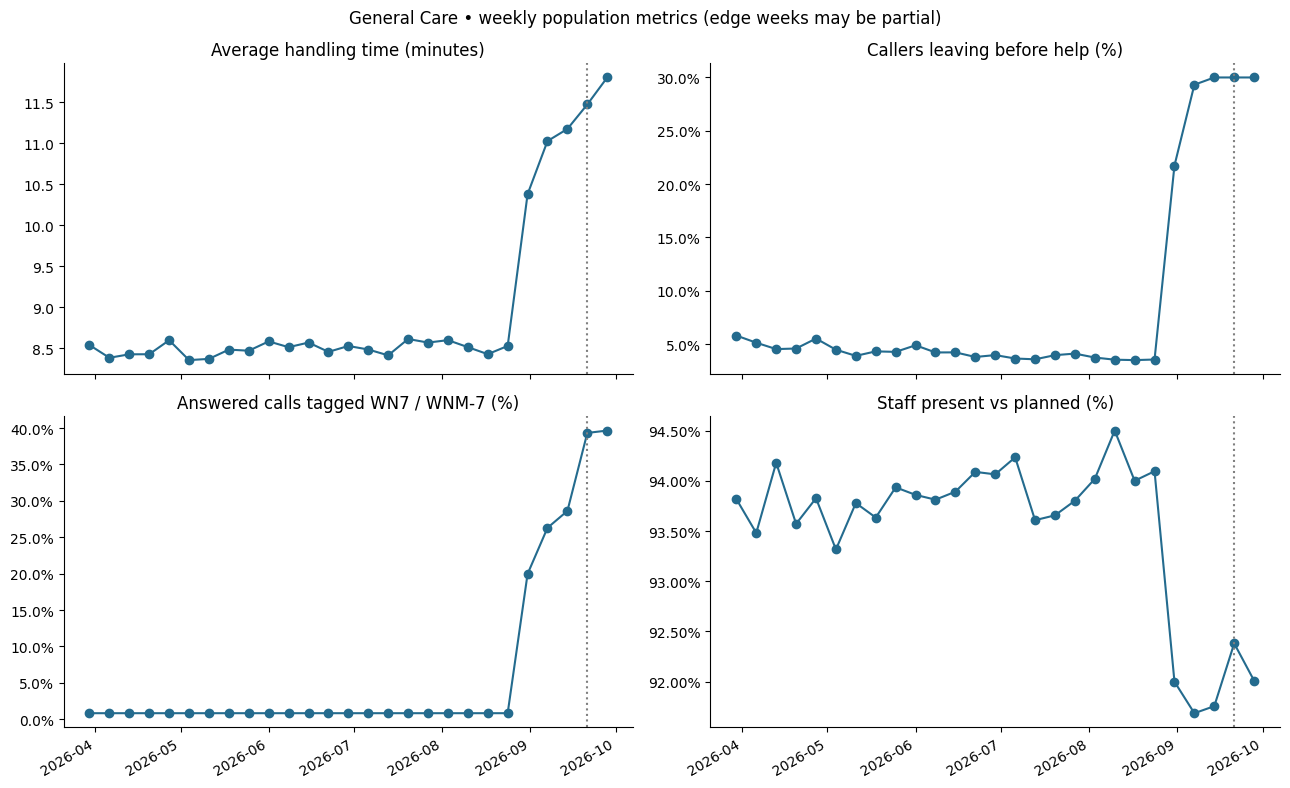

In [4]:
history = ops[ops.Queue.eq(QUEUE) & ops.Date.le(end)].copy()
history['week'] = history.Date.dt.to_period('W-SUN').dt.start_time
weekly = history.groupby('week').apply(population_metrics,include_groups=False)
fig, axes=plt.subplots(2,2,figsize=(13,8),sharex=True)
for axis,col,title in zip(axes.flat,['AHT_min','abandonment','WN7_contact_share','actual_planned'],
 ['Average handling time (minutes)','Callers leaving before help (%)','Answered calls tagged WN7 / WNM-7 (%)','Staff present vs planned (%)']):
 axis.plot(weekly.index,weekly[col],marker='o',color='#246b8e');axis.set_title(title)
 if col != 'AHT_min': axis.yaxis.set_major_formatter(PercentFormatter(1))
 axis.axvline(pd.Timestamp('2026-09-21'),color='grey',ls=':')
fig.suptitle(f'{QUEUE} • weekly population metrics (edge weeks may be partial)')
fig.autofmt_xdate();fig.tight_layout();plt.show()
weekly.to_csv(OUT/'monitor_weekly_population.csv')


Week starting,Eligible calls examined,Both steps completed,Completion rate
Sep 21,143,55,38%
Sep 28,61,21,34%


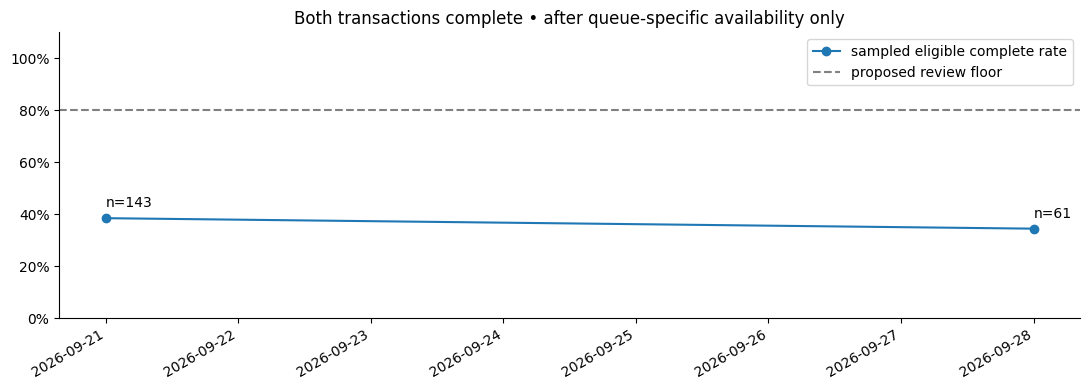

Call reference,Date,Queue,Serial check recorded,Call approach,Replacement arranged,Plus recorded complete,Disposition
ORB-26-000177,2026-09-24,General Care,No,Generic troubleshooting,No,No,Troubleshooting complete
ORB-26-000181,2026-09-28,General Care,Yes,Generic troubleshooting,No,No,Troubleshooting complete
ORB-26-000727,2026-09-25,General Care,Yes,Incomplete recovery,Yes,No,Replacement initiated
ORB-26-001095,2026-09-27,General Care,Yes,Generic troubleshooting,No,No,Troubleshooting complete
ORB-26-001276,2026-09-25,General Care,No,Generic troubleshooting,No,No,Troubleshooting complete
ORB-26-001281,2026-09-30,General Care,No,Generic troubleshooting,No,No,Troubleshooting complete
ORB-26-002194,2026-09-28,General Care,Yes,Generic troubleshooting,No,No,Troubleshooting complete
ORB-26-002195,2026-09-29,General Care,Yes,Generic troubleshooting,No,No,Troubleshooting complete
ORB-26-002375,2026-09-26,General Care,Yes,Generic troubleshooting,No,No,Troubleshooting complete
ORB-26-002379,2026-09-30,General Care,Yes,Generic troubleshooting,No,No,Troubleshooting complete


93 sampled review candidates. Confirm current case/transaction state before any action.


In [5]:
ec = calls[calls.Queue.eq(QUEUE) & calls['Recovery available'] & calls['Call date'].le(end)].copy()
ec['week'] = ec['Call date'].dt.to_period('W-SUN').dt.start_time
wr = ec.groupby('week').apply(recovery_metrics,include_groups=False)
table(pd.DataFrame({'Week starting':wr.index.strftime('%b %d'), 'Eligible calls examined':wr.eligible_n.astype(int), 'Both steps completed':wr.complete_n.astype(int), 'Completion rate':wr.complete_rate.map(lambda v:f'{v:.0%}' if pd.notna(v) else 'No eligible calls')}), '4. Is recovery improving over time?', 'Only sampled eligible calls after this queue gained the recovery path. Short edge weeks and small samples need caution.')
fig,ax=plt.subplots(figsize=(11,4))
if len(wr):
 ax.plot(wr.index,wr.complete_rate,marker='o',label='sampled eligible complete rate')
 for dt,row in wr.iterrows(): ax.annotate(f'n={int(row.eligible_n)}',(dt,row.complete_rate),xytext=(0,8),textcoords='offset points')
 ax.axhline(COMPLETION_REVIEW_FLOOR,color='grey',ls='--',label='proposed review floor')
 ax.set_ylim(0,1.1);ax.yaxis.set_major_formatter(PercentFormatter(1));ax.legend()
ax.set_title('Both transactions complete • after queue-specific availability only')
fig.autofmt_xdate();plt.tight_layout();plt.show()
wr.to_csv(OUT/'monitor_weekly_sample_recovery.csv')
# Review candidates: sampled CALLS, not open cases or unique households. No contact action is taken.
candidates=active_calls[active_calls['Eligible for recovery'].eq('Yes') & ~active_calls['Complete recovery']]
fields=['Call ID','Call date','Queue','Serial verified','Conversation path','Replacement arranged','Northstar Plus attached','Disposition']
table(candidates[fields].head(20).rename(columns={'Call ID':'Call reference','Call date':'Date','Serial verified':'Serial check recorded','Conversation path':'Call approach','Northstar Plus attached':'Plus recorded complete'}), 'Calls to review with Quality', 'Up to 20 sampled calls shown. These are not a list of all open household cases; later resolution is unknown.')
candidates[fields].to_csv(OUT/'sampled_recovery_review_candidates.csv',index=False)
print(len(candidates),'sampled review candidates. Confirm current case/transaction state before any action.')


In [6]:
# QA and feedback are selected/voluntary; filter by call date AND event availability as-of.
q=D['qa_joined']; f=D['feedback_joined']
q=q[q.Queue.eq(QUEUE) & q['Call date'].between(start,end) & q['Review date'].le(AS_OF)]
f=f[f.Queue.eq(QUEUE) & f['Call date'].between(start,end) & f['Response date'].le(AS_OF)]
print('Selected QA reviews in window:',len(q),'; voluntary feedback responses:',len(f))
table(q['Selection reason'].value_counts().rename_axis('Why calls were selected').reset_index(name='Reviews'), '5. How were the quality reviews selected?', 'These are selected reviews, not a representative survey of all calls.')
if len(q):
 table(pd.DataFrame([{'Behavior checked':col,'Calls with behavior recorded':q[col].eq('Yes').sum(),
                       'Calls assessed':q[col].isin(['Yes','No']).sum()} for col in
 ['Acknowledged practical impact','Recognized recovery path','Recap complete']]), 'What reviewers heard', 'Each behavior has its own count of assessed calls; unassessed calls are not treated as failures.')
if len(f):
 table(f.groupby('Conversation path').agg(responses=('Feedback ID','size'),mean_score=('Satisfaction score','mean')).round(1).reset_index().rename(columns={'Conversation path':'What happened on the call','responses':'People who responded','mean_score':'Average rating out of 5'}), 'What responding customers reported', 'Voluntary responses only; small groups can be misleading.')
print('These are sample diagnostics, not population performance ratings.')


Selected QA reviews in window: 107 ; voluntary feedback responses: 377


Why calls were selected,Reviews
Oversample: WN7 recovery risk,48
Oversample: long handle time,48
Routine quality sample,11


Behavior checked,Calls with behavior recorded,Calls assessed
Acknowledged practical impact,75,107
Recognized recovery path,59,107
Recap complete,59,107


What happened on the call,People who responded,Average rating out of 5
Complete recovery,33,4.5
Generic troubleshooting,206,3.0
Incomplete recovery,3,2.3
Recognized not eligible,29,3.4
Standard resolution,106,3.6


These are sample diagnostics, not population performance ratings.


## 6. Who should act on these results?
- **Daily, Care Operations/WFM:** examine abandonment, offered volume, AHT components, coverage and occupancy; review whether coaching must be rescheduled. Annotate notices, staffing changes, search releases, routing, and actual learning exposure dates.
- **Twice weekly, Quality/Team Leads (proposed):** inspect sampled incomplete recovery and ineligible branches, serial verification and recap. Separate system pending/failure from a missed action. Validate a manageable cadence with Elias and Priya rather than add unbudgeted manager work.
- **After two weeks, Dana:** use the pilot gates in notebook 01 and a contemporaneous comparison. Expand only with recovery quality, queue protection, and sufficient evidence. No before/after causal claim from this historical dashboard.

### Questions this report cannot answer yet
 household-level 7-day repeat contacts; order shipment and Plus Applied timestamps; pending backlog and age; unsupported offers to ineligible households; follow-up kept; exposure by shift/tenure; interval service levels. Current data contains call-level transaction flags but cannot verify transaction status histories or later resolution. Add authorized event feeds and a stable household/case key with appropriate access controls before implementing these metrics. Never count sampled review candidates as a population backlog.

### For the colleague refreshing the data
 preserve source copies and hashes; rerun cleaning/joins and inspect audit changes. The analysis notebook retains the supplied historical cutoff. Monitoring passes its explicit `AS_OF` parameter to the loader, so refreshed calls, reviews, and responses must not extend beyond that date. Update `AS_OF` and document the new extract contract when adding genuinely later data; future-date checks remain active. No thresholds or processes here have been implemented at Northstar.


## When the export format or recovery process changes
Routine refreshes need edits only in **EDIT HERE — refresh settings**. Ask the colleague maintaining the notebook to make the following changes when the source itself changes:

| Change | Exact place to update | Check afterwards |
|---|---|---|
| Different workbook names or sheet names | `analysis_utils.py`, `load_data()`, the `specs` mapping; also the workbook list in the **READ NEW FILES HERE** cell and this guide | Every required table loads and the receipt hashes the right files. |
| Renamed columns or different status values | `analysis_utils.py`, `load_data()` cleaning and validation; code cells using those fields | Keep unique identifiers, duplicate checks, staffing joins, and the rule requiring both recovery actions. Do not just suppress an error. |
| Different queues, changed offer, or a newly approved path | `analysis_utils.py`, `load_data()`, the `Recovery available` and `Complete recovery` definitions; `recovery_metrics()` | Confirm the new business rules and effective dates with Care/Product, then review labels and comparisons. Existing rules are specific to this case. |
| Different operating comparison or review triggers | **EDIT HERE — refresh settings**, near the top of this notebook | Record why the baseline or triggers changed so progress remains interpretable. |
| Connecting an API or database in future | Replace the Excel-reading part of `load_data()` with an authorized connector that returns the same validated tables | Credentials belong in secure configuration, never in notebook cells. No such connection exists in this version. |

If workbook headings or fields are missing, restore the agreed format or update the loader with a developer. If joins fail, get matching calls, staffing, and review exports. If a baseline is empty, supply its history or deliberately choose an available baseline. If data is dated after `AS_OF`, correct the report date or supply the appropriate snapshot. Do not bypass checks to obtain a chart.

**Tracking progress after a rollout:** keep a record of actual rollout dates, shifts/Guides included, search/system changes, and staffing changes. The weekly chart shows change over time, but without those extra records it cannot tell whether training caused a change. The supplied sources do not yet contain rollout participation or household-level repeat-call data.

In [7]:
# A successful refresh reaches this final cell without earlier errors.
display(Markdown(f'### Refresh complete\nAll monitoring cells finished for **{QUEUE}**. '
                 f'Data loaded at **{RUN_AT.strftime("%Y-%m-%d %H:%M UTC")}**; '
                 f'operating window **{start.date()}–{end.date()}**. '
                 'Save this notebook to retain these results.'))

### Refresh complete
All monitoring cells finished for **General Care**. Data loaded at **2026-11-06 03:55 UTC**; operating window **2026-09-24–2026-09-30**. Save this notebook to retain these results.